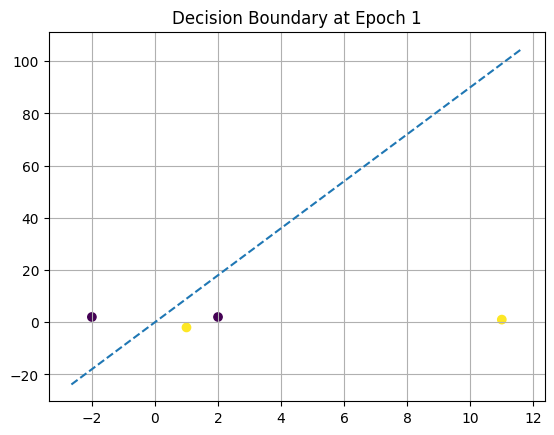

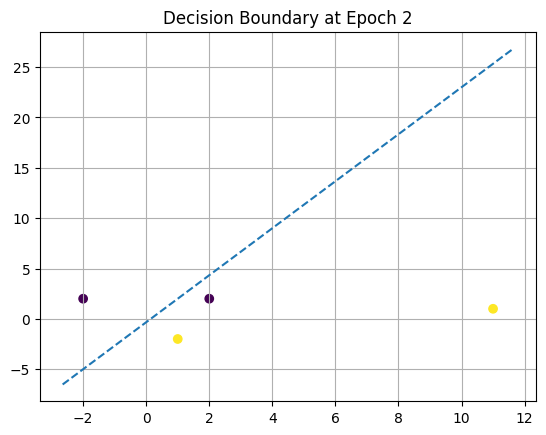

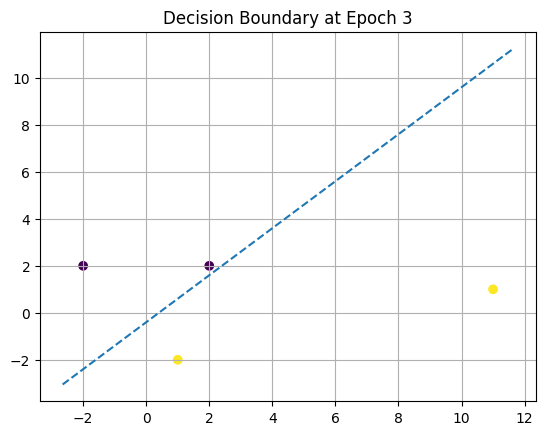

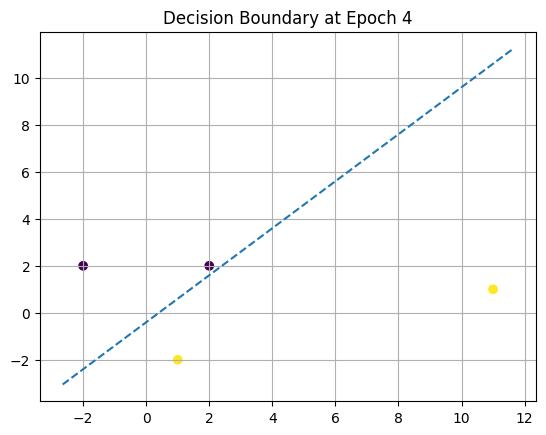

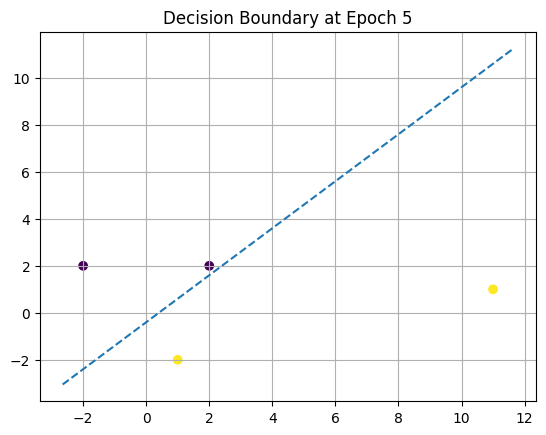

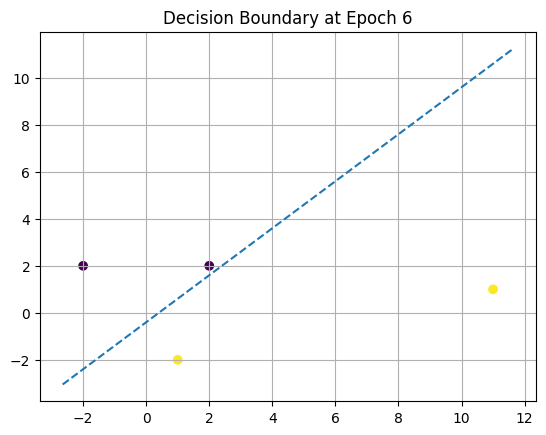

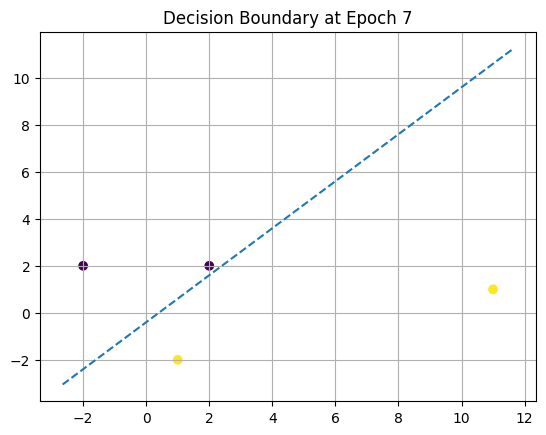

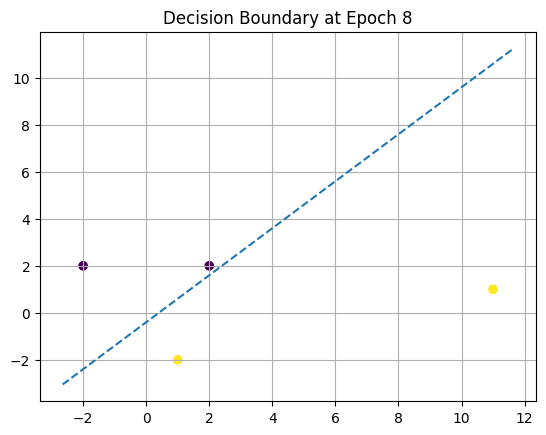

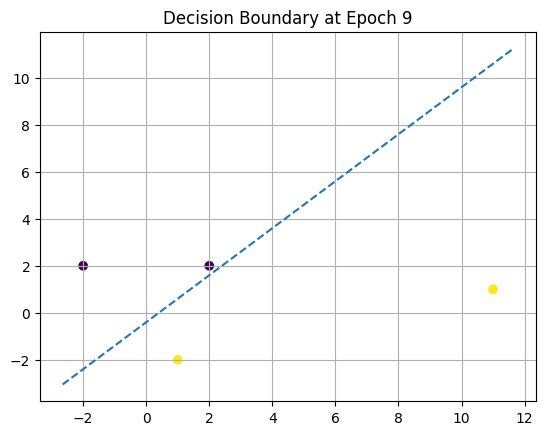

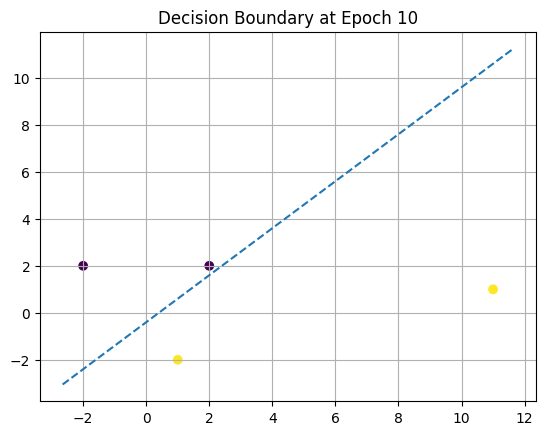

Final Weights: [ 5. -5.]
Final Bias: -2
Input: [2 2], Prediction: 0
Input: [ 1 -2], Prediction: 1
Input: [-2  2], Prediction: 0
Input: [11  1], Prediction: 1


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
def hard_limit(x):
    return np.where(x >= 0, 1, 0) # if the incoming value is >=0, the outputs 1. If it is less than 0, it outputs 0
def initialize_weights(input_size):
    return {'w': np.zeros(input_size), 'b': 0}

def predict(X, weights):
    return hard_limit((np.dot(weights['w'], X) + weights['b']))

def train(X_train, y_train, weights, epochs=10):
    for epoch in range(epochs):
        for X, y in zip(X_train, y_train):
            prediction = predict(X, weights)
            weights['w'] += (y - prediction) * X
            weights['b'] += (y - prediction)
        plot_decision_boundary(X_train, y_train, weights, epoch)
    return weights

def plot_decision_boundary(X_train, y_train, weights, epoch):
    plt.figure()
    plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train)
    xmin, xmax = plt.xlim()

    x = np.linspace(xmin, xmax, 100)
    y = -(weights['w'][0] * x + weights['b']) / weights['w'][1]
    plt.plot(x, y, '--')

    plt.title(f'Decision Boundary at Epoch {epoch + 1}')
    plt.grid(True)
    plt.show()


X_train = np.array([[2, 2], [1, -2], [-2, 2], [11, 1]])

y_train = np.array([0, 1, 0, 1])

input_size = X_train.shape[1]

epochs = 10

weights = initialize_weights(input_size)
weights = train(X_train, y_train, weights, epochs)

print("Final Weights:", weights['w'])
print("Final Bias:", weights['b'])

for X in X_train:
    print(f"Input: {X}, Prediction: {predict(X, weights)}")